## Import

In [1]:
%reset -f
import tensorflow as tf
import numpy as np
import copy as cp
import scipy.sparse.linalg as linalg
import matplotlib.pyplot as plt
from time import time

tf.get_logger().setLevel('ERROR')
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
  tf.config.experimental.set_memory_growth(gpu, True)

## Paramètres du problème

In [2]:
# Set data type
DTYPE='float32'
tf.keras.backend.set_floatx(DTYPE)

# Set constants
pi = tf.constant(np.pi, dtype=DTYPE)

# Set boundary
tmin = 0.
tmax = 1.
xmin = -1.
xmax = 1.

numin = 1e-4
numax=  1e-2

# Lower bounds
lb = tf.constant([tmin, xmin, numin], dtype=DTYPE)
# Upper bounds
ub = tf.constant([tmax, xmax, numax], dtype=DTYPE)

# Define initial condition
def fun_u_0(x):
    return -tf.sin(pi * x)

# Define boundary condition
def fun_u_b(t, x):
    n = x.shape[0]
    return tf.zeros((n,1), dtype=DTYPE)

## données 

In [3]:
def gen_train_data(N_r=10_000):

  # Set random seed for reproducible results
  tf.random.set_seed(0)

  # uniformly sampled collocation points
  t_r = tf.random.uniform((N_r,1), lb[0], ub[0], dtype=DTYPE)
  x_r = tf.random.uniform((N_r,1), lb[1], ub[1], dtype=DTYPE)
  nu_r = tf.random.uniform((N_r,1), lb[2], ub[2], dtype=DTYPE)
  X_r = tf.concat([t_r, x_r, nu_r], axis=1)

  return X_r

In [4]:
X_r = gen_train_data(1_000)

## PINN model

In [5]:
class PhysicsInformedNN(tf.keras.Model):
    """ Set basic architecture of the PINN model."""

    def __init__(self, lb, ub, 
            output_dim=1,
            num_hidden_layers=8, 
            num_neurons_per_layer=20,
            activation='tanh',
            kernel_initializer='glorot_normal',
            **kwargs):
        super().__init__(**kwargs)

        self.num_hidden_layers = num_hidden_layers
        self.output_dim = output_dim
        self.lb = lb
        self.ub = ub
        
        # Define NN architecture
        self.scale = tf.keras.layers.Lambda(
            lambda x: 2.0*(x - lb)/(ub - lb) - 1.0)
        self.hidden = [tf.keras.layers.Dense(num_neurons_per_layer,
                             activation=tf.keras.activations.get(activation),
                             kernel_initializer=kernel_initializer)
                           for _ in range(self.num_hidden_layers)]
        self.out = tf.keras.layers.Dense(output_dim)

    def call_before(self,X):
        """Forward-pass through neural network."""
        
        Z = self.scale(X)
        for i in range(self.num_hidden_layers):
            Z = self.hidden[i](Z)
        Y = self.out(Z)
        
        return Y
        
        
    def call(self, X):
        """Call with imposed IC/BC"""
        
        # passage dans le NN
        Y = self.call_before(X)

        # imposer conditions au bords
        t, x = X[:,0:1], X[:,1:2]
        tanh_t = tf.tanh(t)
    
        return (1-tanh_t)*fun_u_0(x) + (x+1)*(1-x)*tanh_t*Y

## chargement du modèle déja entrainé

In [6]:
model = PhysicsInformedNN(lb, ub, num_hidden_layers=10, num_neurons_per_layer=150, activation='tanh')
model(X_r[:10])

# avec le residu ou l'entropie
model.load_weights('best_weight_residu.h5')
#model.load_weights('best_weight_entropie.h5')

## visualisation

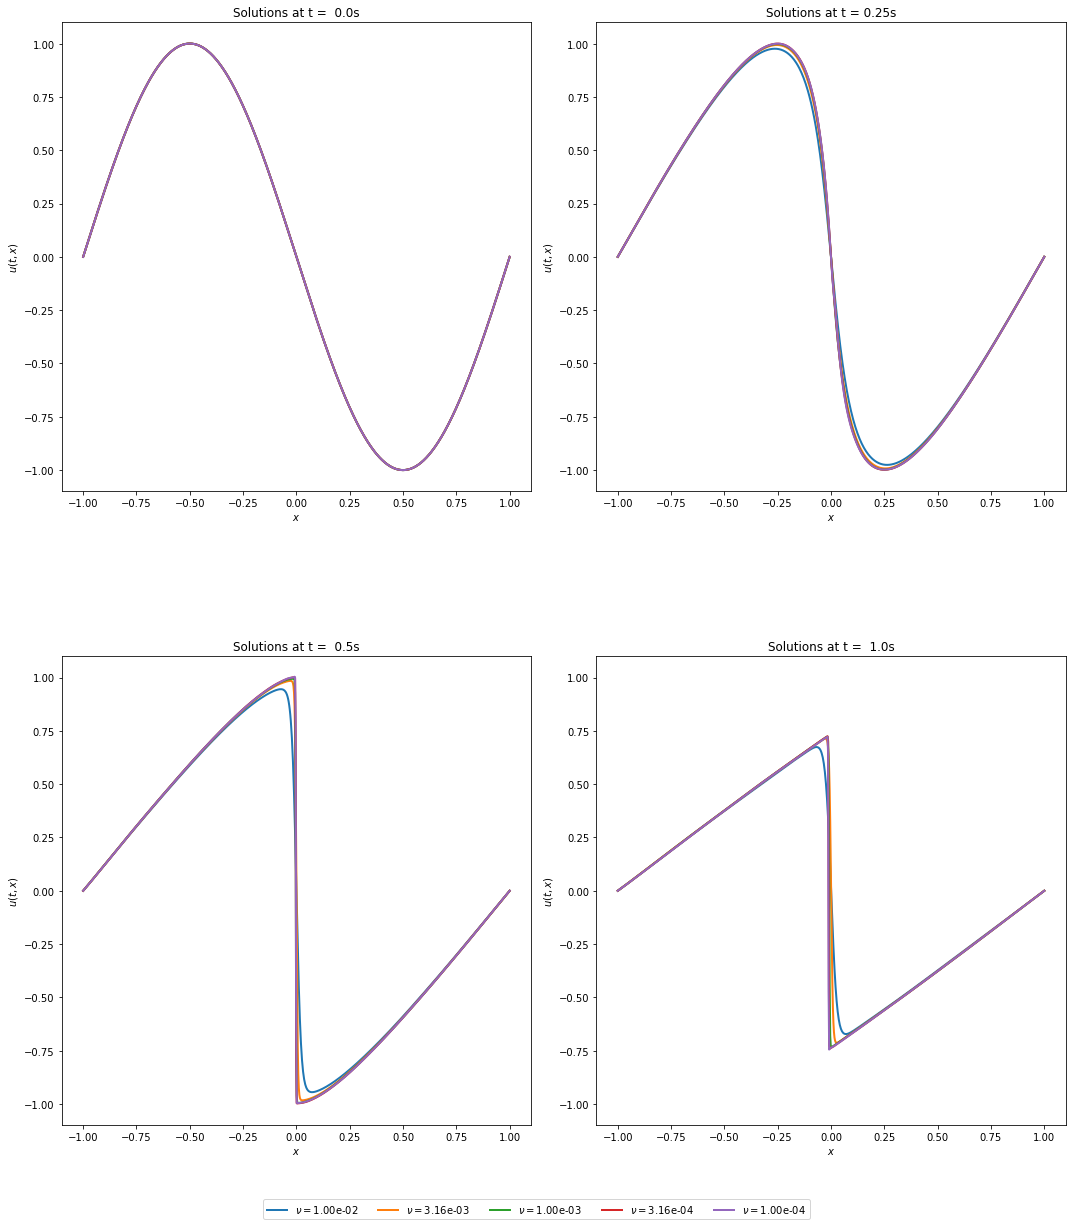

In [7]:
N = 800

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(15,18))
axs = axs.flatten()

all_times = [0., 0.25, 0.5, 1.0]

for i,end_time in enumerate(all_times):
    
    for visc in np.logspace(-2, -4, 5):

      # solution en utilisant le PINN
      xspace = np.linspace(-1,1,N)
      T, X = np.meshgrid(end_time, xspace)
      nuspace = visc * np.ones(N)
      Xgrid = np.vstack([T.flatten(), X.flatten(), nuspace.flatten()]).T
      upred = model(tf.cast(Xgrid,DTYPE))
      upred = tf.reshape(upred, (1,N))[0].numpy()

      axs[i].plot(xspace, upred, '-', linewidth = 2, label=r'$\nu=${:4.2e}'.format(visc))

      axs[i].set_xlabel('$x$')
      axs[i].set_ylabel('$u(t,x)$')    
      axs[i].axis('square')
      axs[i].set_xlim([-1.1,1.1])
      axs[i].set_ylim([-1.1,1.1]);
      axs[i].set_title('Solutions at t = {:4.2}s'.format(end_time));


handles, labels = axs[-1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=5);
fig.tight_layout()
#plt.savefig('./figures/Burgers{:03d}'.format(i), bbox_inches = 'tight')

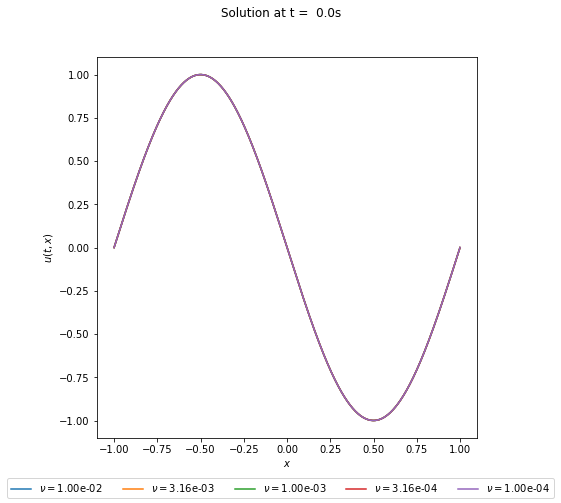

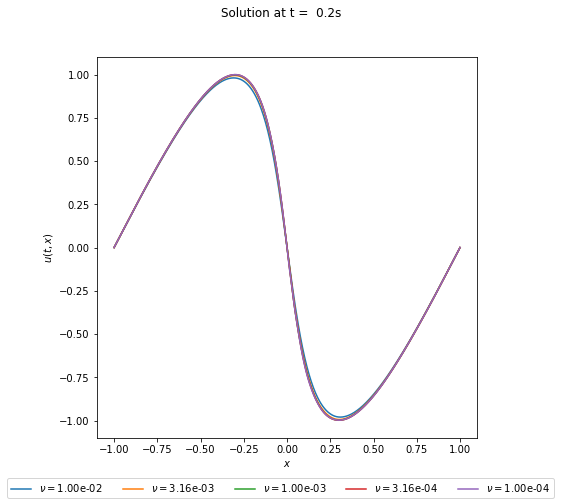

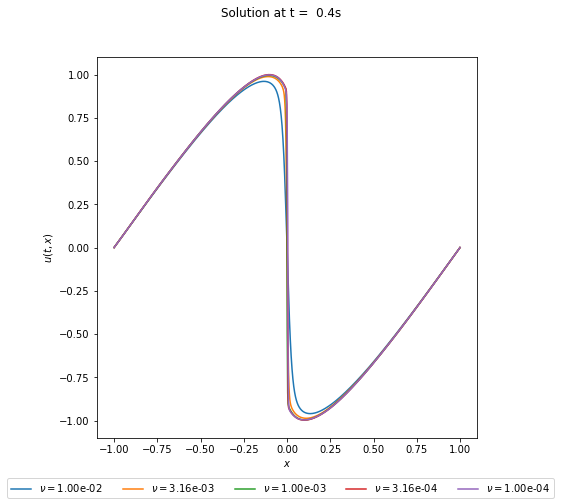

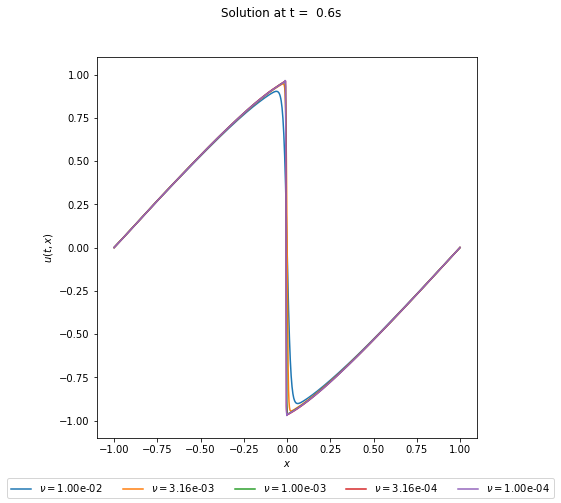

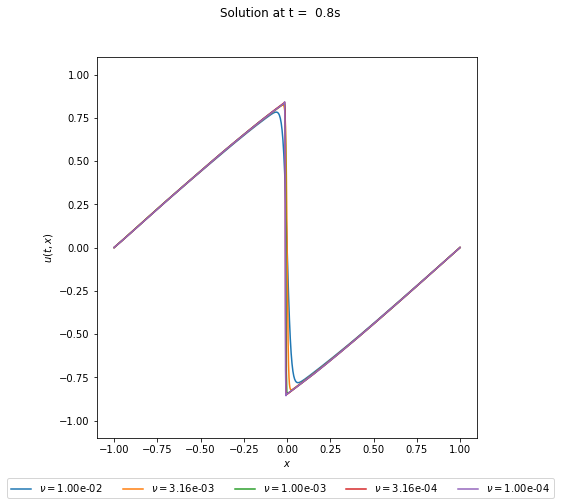

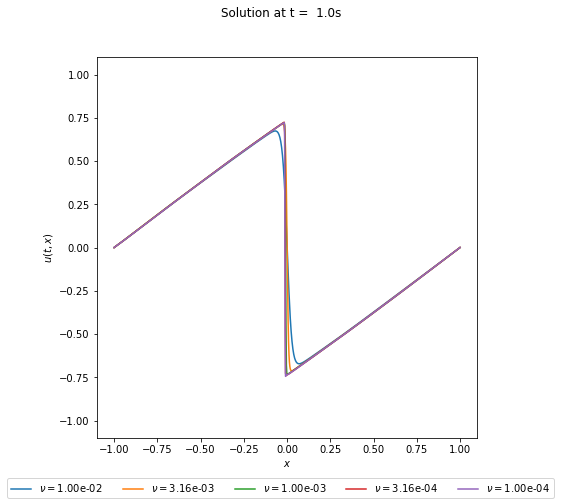

In [8]:
N = 800

all_times = np.linspace(0,1,6)
for i,end_time in enumerate(all_times):

    fig, ax = plt.subplots(1, 1, figsize=(7, 7))
    for visc in np.logspace(-2, -4, 5):


      # solution en utilisant le PINN
      xspace = np.linspace(-1,1,N)
      T, X = np.meshgrid(end_time, xspace)
      nuspace = visc * np.ones(N)
      Xgrid = np.vstack([T.flatten(), X.flatten(), nuspace.flatten()]).T
      upred = model(tf.cast(Xgrid,DTYPE))
      upred = tf.reshape(upred, (1,N))[0].numpy()

      ax.plot(xspace, upred, '-', linewidth = 1.5, label=r'$\nu=${:4.2e}'.format(visc))

      ax.set_xlabel('$x$')
      ax.set_ylabel('$u(t,x)$')    
      ax.axis('square')
      ax.set_xlim([-1.1,1.1])
      ax.set_ylim([-1.1,1.1]);

    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=5);
    plt.suptitle('Solution at t = {:4.2}s'.format(end_time));
    #plt.savefig('./figures/Burgers{:03d}'.format(i), bbox_inches = 'tight')

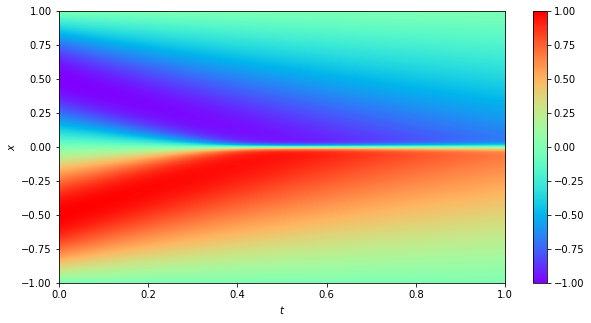

In [9]:
N=1000
visc = 1e-2
xspace = np.linspace(-1,1,N)
tspace = np.linspace(0,1,N)
T, X = np.meshgrid(tspace, xspace)
nuspace = visc * np.ones(N*N)
Xgrid = np.vstack([T.flatten(), X.flatten(), nuspace.flatten()]).T
upred = model(tf.cast(Xgrid,DTYPE))
U = upred.numpy().reshape(N,N)

# plot solution
fig = plt.figure(figsize=(10,5))
ax = fig.add_subplot(111)
ax.set_xlabel('$t$')
ax.set_ylabel('$x$')  
img = ax.imshow(U, cmap='rainbow', origin='lower', extent=[0.,1.,-1.,1.], 
                aspect='auto', interpolation='nearest',
               vmin = -1., vmax = 1.)
fig.colorbar(img);
#plt.savefig('./figures/Burgers')

In [10]:
def get_residual(model, X_r):
    """fonction qui calcule le résidu"""
    
    # Split t and x to compute partial derivatives
    t, x = X_r[:, 0:1], X_r[:,1:2]
    nu = X_r[:,2:3]
        
    with tf.GradientTape(persistent=True) as tape:
        # Watch variables representing t and x during this GradientTape
        tape.watch(t)
        tape.watch(x)

        # Compute current values u(t,x) and u(t,x)^2
        u = model(tf.stack([t[:,0], x[:,0], nu[:,0]], axis=1))
        u2 = tf.square(u)

        u_x = tape.gradient(u, x)

    u_t = tape.gradient(u, t)
    u_xx = tape.gradient(u_x, x)
    u2_x = tape.gradient(u2, x)

    del tape

    return u_t + u2_x/2. - nu * u_xx

In [11]:
N_val = 50_000
tspace = np.linspace(tmin,tmax,N_val)
xspace = np.linspace(xmin,xmax,N_val)
nuspace = np.linspace(numin,numax,N_val)

X_val = np.vstack([tspace.flatten(), xspace.flatten(), nuspace.flatten()]).T
X_val = tf.cast(X_val,DTYPE)

tf.reduce_mean(tf.square(get_residual(model, X_val)))

<tf.Tensor: shape=(), dtype=float32, numpy=7.84036e-06>

## comparaison avec la solution exacte

In [12]:
# Classe résolvant Burgers avec des volumes finis 1D (cours P. Helluy)
class EDP:
    def __init__(self,Nx,viscosity, u_0):
      
        self.Nx=Nx  # nb mailles
        self.a=-1.0  # bord gauche du domaine
        self.b=1.0  # bord droit du domaine
        self.viscosity = viscosity
        self.dt=0.0
        self.u_0 = u_0       

        # Pour le maillage Nx mailles et 2 maillages fantome a gauche et droite pour les conditions limites
        self.h=(self.b-self.a)/self.Nx  # pas de maillage
        self.begin = 1  # numéro de la première maille non fantome
        self.end=  self.Nx+1  # numéro de la dernière maille non fantome  
        
        self.nodes=np.linspace(self.a-self.h,self.b+self.h,self.Nx+3) 
        #listes des noeuds: n+1 noeuds et 2 noeuds fantomes
        self.cells=np.linspace(self.a-0.5*self.h,self.b+0.5*self.h,self.Nx+2)
        #listes des centres de mailles: n centres et 2 centres fantomes
        self.rho= np.zeros(self.Nx+2) ## rho sur le maillage + mailles fantomes
    
    #fonction pour initialiser rho
    def init(self):
    
        for i in range(0,len(self.rho)):
            self.rho[i]=self.u_0(self.cells[i])
    
        # on conserve le rho initiale
        self.rho_0=cp.copy(self.rho)

    # flux volumes finis de Lax-Friedrichs
    def flux_hyp_burgers(self,rl,rr):
        center = 0.5*(0.5*rl*rl+0.5*rr*rr)
        vel = max(abs(rl),abs(rr))
        visco=0.5*vel*(rl-rr)
        return center+visco
        
    # flux volumes finis du terme de diffusion
    def flux_diff(self,rl,rr):
        grad = self.viscosity*(rr-rl)/self.h
        return grad
    
    # plot de rho_0 et de rho
    def plot(self):
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        axes[0].plot(self.cells[self.begin:self.end],self.rho_0[self.begin:self.end],'r-')
        axes[1].plot(self.cells[self.begin:self.end],self.rho[self.begin:self.end],'b-')
        
    # condition limite dans les mailles fantomes selon le cas test. A expliquer
    def bc(self):
        self.rho[0]=0
        self.rho[-1]=0
    
    # le terme de diffusion est traité par un schéma implicite en temps
    # le terme de Burgers par un schema implicite
    # Ici on contruit le produit matrice vecteur entre la matrice implicite et un vecteur v
    def matvec_Laplacian(self,v):
        res=np.zeros(self.Nx)
        vl=0.0
        vr=0.0

        res[0]= v[0]-self.dt*self.viscosity/(self.h**2.0)*(vl-2.0*v[0]+v[1])
        for i in range(1,self.Nx-1):
            res[i]= v[i]-self.dt*self.viscosity/(self.h**2.0)*(v[i-1]-2.0*v[i]+v[i+1])
            
        res[-1]= v[-1]-self.dt*self.viscosity/(self.h**2.0)*(v[-2]-2.0*v[-1]+vr)
        return res
        
    # Résolution de l'équation en temps
    # A est un opérateur linéaire associée à la matrice implicite (le produit matrice vecteur)
    # on a pas besoin de construire la matrice pour résoudre un problème avec le gradient conjugé.
    # Il suffit juste de donner ce produit matrice vecteur
    def solve_loc(self,T,flux):
        sol=[]
        nt = 0
        time = 0.0
        rho_temp = np.zeros(self.Nx)
        self.A = linalg.LinearOperator((self.Nx,self.Nx), matvec=self.matvec_Laplacian)
        while time < T:
            # vitesse max de l'équation utile pour CFL
            vmax=max(abs(self.rho[self.begin:self.end]))
            self.dt= 0.5*self.h/vmax
            for i in range(0,self.Nx):
                # calcul des conditions limites dans la mailles fantomes
                self.bc()
                rhol = self.rho[self.begin+i-1]
                rhoc = self.rho[self.begin+i]
                rhor = self.rho[self.begin+i+1]
                # calcul des flux explicite
                fh=flux(rhoc,rhor)-flux(rhol,rhoc)
                # schéma en temps explicite
                rho_temp[i]=rhoc -self.dt/self.h*fh
        
            # schéma en temps implicite en résovlant Arho^{n+1}= Explicit
            self.rho[self.begin:self.end],info=linalg.cg(self.A,rho_temp,x0=None,tol=1e-06,maxiter=200)
            sol.append(cp.copy(self.rho[self.begin:self.end]))
            time=time+self.dt
            nt=nt+1
        return sol
    
    def solve(self,T):
        sol=self.solve_loc(T,self.flux_hyp_burgers)
        return sol

def u_0(x):
  return -np.sin(np.pi*x)

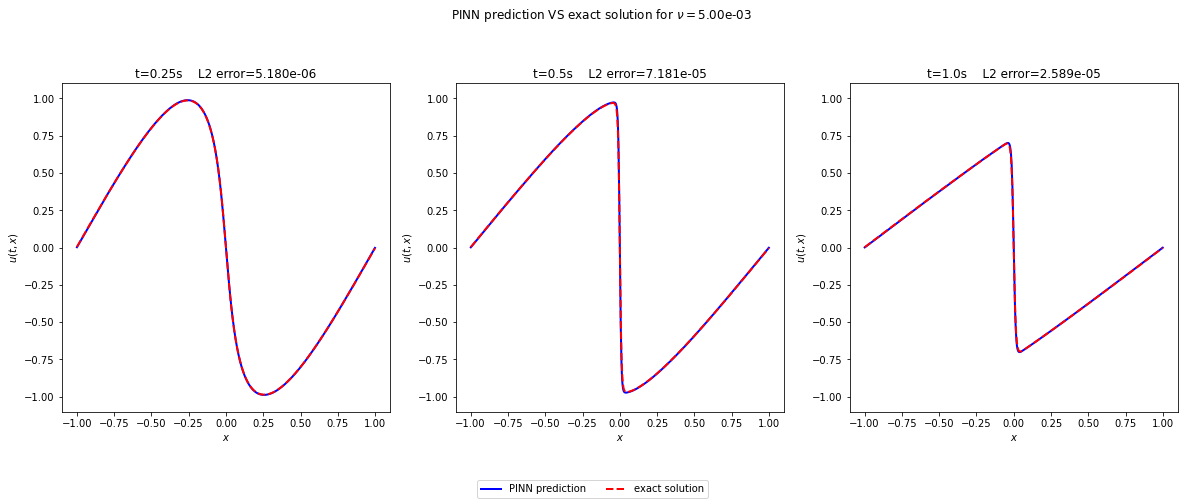

In [14]:
N = 800
visc = 5e-3

bg=EDP(N, visc, u_0)
x = bg.cells[bg.begin:bg.end]

fig, ax = plt.subplots(1, 3, figsize=(20, 7))

all_times = [0.25, 0.5, 1.0]
for i_t, end_time in enumerate(all_times):

  bg.init()
  sol=bg.solve(end_time)
  exact_sol = sol[-1]

  # solution en utilisant le PINN
  T, X = np.meshgrid(end_time, x)
  nuspace = visc * np.ones(N)
  Xgrid = np.vstack([T.flatten(),x.flatten(), nuspace.flatten()]).T
  upred = model(tf.cast(Xgrid,DTYPE))
  upred = tf.reshape(upred, (1,N))[0].numpy()

  # affichage
  erreurL2 = (x[-1]-x[0])/N*np.sum((exact_sol-upred)**2)
  title = "t={}s    L2 error={:5.3e}".format(end_time, erreurL2)
  ax[i_t].set_title(title)

  ax[i_t].plot(x, upred, 'b-', linewidth = 2, label="PINN prediction")
  ax[i_t].plot(x, exact_sol, 'r--', linewidth = 2, label="exact solution")

  ax[i_t].set_xlabel('$x$')
  ax[i_t].set_ylabel('$u(t,x)$')    
  ax[i_t].axis('square')
  ax[i_t].set_xlim([-1.1,1.1])
  ax[i_t].set_ylim([-1.1,1.1]);

handles, labels = ax[-1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2);
plt.suptitle(r"PINN prediction VS exact solution for $\nu=${:4.2e}".format(visc));